In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

df = pd.read_csv("flight_train.csv")
print(df.shape)
df.info()
df.head()

(15589, 12)
<class 'pandas.DataFrame'>
RangeIndex: 15589 entries, 0 to 15588
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                15589 non-null  int64  
 1   airline           12500 non-null  str    
 2   flight            15589 non-null  str    
 3   source_city       15589 non-null  str    
 4   departure_time    15589 non-null  str    
 5   stops             15589 non-null  str    
 6   arrival_time      15589 non-null  str    
 7   destination_city  15589 non-null  str    
 8   flight_class      15589 non-null  str    
 9   duration          12494 non-null  float64
 10  days_left         15589 non-null  int64  
 11  price             15589 non-null  int64  
dtypes: float64(1), int64(3), str(8)
memory usage: 1.4 MB


,id,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,flight_class,duration,days_left,price
0,1,Wayfarer Aviation,IX 1070,Metropolis,Evening,zero,Night,Springfield,Economy,NaN,18,8909
1,2,Oceanic Airlines,6E 285,Los Santos,Night,zero,Night,Springfield,Economy,1.33,38,5115
2,3,Wayfarer Aviation,AI 2641,Night City,Evening,zero,Night,Springfield,Business,2.08,13,35247
3,4,Oceanic Airlines,6E 6704,Night City,Afternoon,zero,Evening,Metropolis,Economy,2.25,5,6457
4,5,Oceanic Airlines,6E 234,Hill Valley,Evening,one,Night,Springfield,Economy,4.83,21,6842


In [36]:
df = df.drop(columns=["id", "airline"])

# split flight into airline code and number
df["flight_code"] = df["flight"].str.strip().str.upper().str[:2]
df["flight_number"] = df["flight"].str[2:].str.strip().astype(int)
df = df.drop(columns=["flight"])

# stops to int, class to 0/1
df["stops"] = df["stops"].map({"zero": 0, "one": 1, "two_or_more": 2})
df["flight_class"] = df["flight_class"].map({"Economy": 0, "Business": 1})

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15589 entries, 0 to 15588
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   source_city       15589 non-null  str    
 1   departure_time    15589 non-null  str    
 2   stops             15589 non-null  int64  
 3   arrival_time      15589 non-null  str    
 4   destination_city  15589 non-null  str    
 5   flight_class      15589 non-null  int64  
 6   duration          12494 non-null  float64
 7   days_left         15589 non-null  int64  
 8   price             15589 non-null  int64  
 9   flight_code       15589 non-null  str    
 10  flight_number     15589 non-null  int64  
dtypes: float64(1), int64(5), str(5)
memory usage: 1.3 MB


Predicting Duration values using ML

In [37]:
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor, HistGradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

# Only rows with a known duration. Price is NOT used as a feature (test has no price).
known = df.dropna(subset=["duration"]).copy()

cat_cols = ["flight_code", "source_city", "destination_city", "departure_time", "arrival_time"]
num_cols = ["stops", "flight_class", "flight_number"]

X = pd.get_dummies(known[cat_cols + num_cols], columns=cat_cols, dtype=int)
y = known["duration"]
print(X.shape, y.shape)

(12494, 46) (12494,)


In [38]:
models = {
    "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=1, n_jobs=-1, random_state=42),
    "Extra Trees": ExtraTreesRegressor(n_estimators=300, min_samples_leaf=1, n_jobs=-1, random_state=42),
    "Hist Gradient Boosting": HistGradientBoostingRegressor(max_iter=500, learning_rate=0.05, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=8, n_jobs=-1, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=500, learning_rate=0.05, num_leaves=63,
                              min_child_samples=5, random_state=42, verbose=-1),
    "CatBoost": CatBoostRegressor(iterations=500, learning_rate=0.05, depth=8, random_state=42, verbose=0),
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)
one_stop = (known["stops"] == 1).values

rows = []
for name, model in models.items():
    pred = cross_val_predict(model, X, y, cv=cv)      # each row predicted by a model that never saw it
    err = np.abs(pred - y.values)
    rows.append({
        "model": name,
        "MAE (h)": err.mean(),
        "RMSE (h)": np.sqrt(mean_squared_error(y, pred)),
        "one-stop MAE (h)": err[one_stop].mean(),
        "% off by >1h": (err > 1).mean() * 100,
    })
    print(f"{name}: MAE={err.mean():.3f}h")

results = pd.DataFrame(rows).set_index("model").sort_values("MAE (h)").round(3)
results

Random Forest: MAE=0.125h
Extra Trees: MAE=0.109h
Hist Gradient Boosting: MAE=0.224h
XGBoost: MAE=0.134h
LightGBM: MAE=0.148h
CatBoost: MAE=0.229h


,MAE (h),RMSE (h),one-stop MAE (h),% off by >1h
model,,,,
Extra Trees,0.109,0.845,0.332,2.305
Random Forest,0.125,0.801,0.378,2.593
XGBoost,0.134,0.823,0.380,2.169
LightGBM,0.148,0.815,0.398,2.481
Hist Gradient Boosting,0.224,0.860,0.572,3.882
CatBoost,0.229,0.779,0.555,3.546


In [39]:
best_name = results.index[0]
print("Best model:", best_name)
best_model = models[best_name]

Best model: Extra Trees


In [40]:
missing = df["duration"].isna()
print("missing before:", missing.sum())

# same features as training; align columns to the training matrix
X_missing = pd.get_dummies(df.loc[missing, cat_cols + num_cols], columns=cat_cols, dtype=int)
X_missing = X_missing.reindex(columns=X.columns, fill_value=0)

# fit the best model on all rows with a known duration, then predict the missing ones
best_model.fit(X, y)
df.loc[missing, "duration"] = best_model.predict(X_missing)

print("missing after:", df["duration"].isna().sum())
df["duration"].describe()

missing before: 3095
missing after: 0


count    15589.000000
mean         4.291440
std          4.167888
min          0.920000
25%          2.255667
50%          2.500000
75%          4.920000
max         38.080000
Name: duration, dtype: float64

In [41]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15589 entries, 0 to 15588
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   source_city       15589 non-null  str    
 1   departure_time    15589 non-null  str    
 2   stops             15589 non-null  int64  
 3   arrival_time      15589 non-null  str    
 4   destination_city  15589 non-null  str    
 5   flight_class      15589 non-null  int64  
 6   duration          15589 non-null  float64
 7   days_left         15589 non-null  int64  
 8   price             15589 non-null  int64  
 9   flight_code       15589 non-null  str    
 10  flight_number     15589 non-null  int64  
dtypes: float64(1), int64(5), str(5)
memory usage: 1.3 MB


In [42]:
# route = source x destination (direction matters: A_to_B is priced differently from B_to_A)
df["route"] = df["source_city"] + "_to_" + df["destination_city"]
df = df.drop(columns=["source_city", "destination_city", "flight_number"])

# one-hot encode the remaining text columns
df = pd.get_dummies(df, columns=["route", "departure_time", "arrival_time", "flight_code"], dtype=int)

print("duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print(df.shape)

df.info()

duplicate rows: 892
(14697, 66)
<class 'pandas.DataFrame'>
RangeIndex: 14697 entries, 0 to 14696
Data columns (total 66 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   stops                             14697 non-null  int64  
 1   flight_class                      14697 non-null  int64  
 2   duration                          14697 non-null  float64
 3   days_left                         14697 non-null  int64  
 4   price                             14697 non-null  int64  
 5   route_Gotham_to_Hill Valley       14697 non-null  int64  
 6   route_Gotham_to_Los Santos        14697 non-null  int64  
 7   route_Gotham_to_Metropolis        14697 non-null  int64  
 8   route_Gotham_to_Night City        14697 non-null  int64  
 9   route_Gotham_to_Springfield       14697 non-null  int64  
 10  route_Hill Valley_to_Gotham       14697 non-null  int64  
 11  route_Hill Valley_to_Los Santos   14697 non-nu

now we look into the Test Data given to see if there is something that the training data does not have and prepare for it accordingly

In [43]:
train_raw = pd.read_csv("flight_train.csv")
test_raw = pd.read_csv("flight_test.csv")

for d in (train_raw, test_raw):
    d["flight_code"] = d["flight"].str.strip().str.upper().str[:2]
    d["route"] = d["source_city"] + "_to_" + d["destination_city"]

# categories that appear in test but not in train
for col in ["flight_code", "route", "departure_time", "arrival_time", "stops", "flight_class"]:
    new = set(test_raw[col].dropna()) - set(train_raw[col].dropna())
    n_rows = test_raw[col].isin(new).sum()
    print(f"{col:15s} unseen in train: {sorted(new) if new else 'none'}  ({n_rows} test rows)")

# numeric ranges
for col in ["days_left", "duration"]:
    print(f"{col:10s} train: {train_raw[col].min()} - {train_raw[col].max()} | test: {test_raw[col].min()} - {test_raw[col].max()}")

# test rows whose airline code is rare (<50 rows) in train, or missing from train
train_counts = train_raw["flight_code"].value_counts()
common = train_counts[train_counts >= 50].index
print("test rows whose code is rare (<50 in train) or unseen:", (~test_raw["flight_code"].isin(common)).sum())

flight_code     unseen in train: ['BG']  (1 test rows)
route           unseen in train: none  (0 test rows)
departure_time  unseen in train: none  (0 test rows)
arrival_time    unseen in train: none  (0 test rows)
stops           unseen in train: none  (0 test rows)
flight_class    unseen in train: none  (0 test rows)
days_left  train: 1 - 57 | test: 1 - 57
duration   train: 0.92 - 38.08 | test: 0.92 - 29.08
test rows whose code is rare (<50 in train) or unseen: 29


The train and test datasets have similar ranges for `days_left`, `duration`, and most categorical features. However, `flight_code` contains one unseen value (`BG`) and 29 test rows have rare or unseen flight codes. These rows may be harder for the model to predict accurately.

To tackle this we can prepare the training data such that it handles both unknown and very-rare data the same way. We can create an Unknown flight code which will comprise of the very-rare train data flight codes and in the test run, this will account for unknown and same rare flight codes

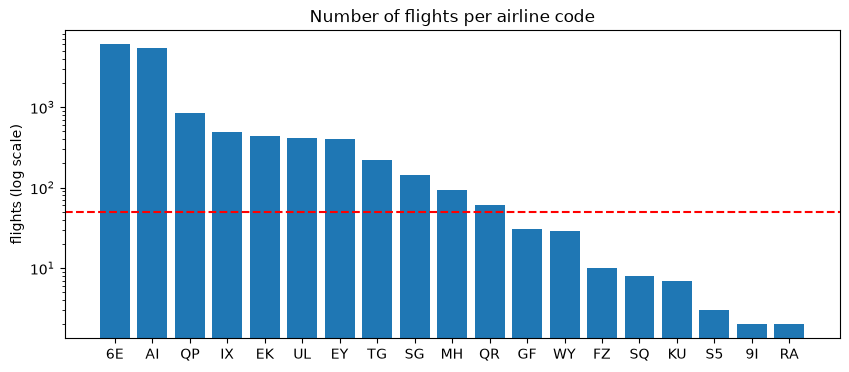

In [44]:
import matplotlib.pyplot as plt

counts = df[[c for c in df.columns if c.startswith("flight_code_")]].sum().sort_values(ascending=False)
counts.index = counts.index.str.replace("flight_code_", "")

plt.figure(figsize=(10, 4))
plt.bar(counts.index, counts.values)
plt.yscale("log")
plt.axhline(50, color="red", linestyle="--")   # grouping cutoff
plt.title("Number of flights per airline code")
plt.ylabel("flights (log scale)")
plt.show()

Using above graph, having <50 rows seems an adequate enough threshold for the flight code to be considered rare. 
Although it comprises of 8 out of 19 different codes.

In [45]:
MIN_ROWS = 50

code_cols = [c for c in df.columns if c.startswith("flight_code_")]
counts = df[code_cols].sum().sort_values()
print(counts)

rare = counts[counts < MIN_ROWS].index.tolist()
df["flight_code_other"] = df[rare].sum(axis=1)
df = df.drop(columns=rare)

keep_codes = [c.replace("flight_code_", "") for c in code_cols if c not in rare]
print("grouped into other:", rare)

flight_code_9I       2
flight_code_RA       2
flight_code_S5       3
flight_code_KU       7
flight_code_SQ       8
flight_code_FZ      10
flight_code_WY      29
flight_code_GF      31
flight_code_QR      60
flight_code_MH      93
flight_code_SG     142
flight_code_TG     223
flight_code_EY     401
flight_code_UL     408
flight_code_EK     432
flight_code_IX     497
flight_code_QP     839
flight_code_AI    5499
flight_code_6E    6011
dtype: int64
grouped into other: ['flight_code_9I', 'flight_code_RA', 'flight_code_S5', 'flight_code_KU', 'flight_code_SQ', 'flight_code_FZ', 'flight_code_WY', 'flight_code_GF']


In [46]:
price_rs = df["price"].copy()        # rupees, kept for reporting
df["price"] = np.log1p(df["price"])
df["price"].describe()

count    14697.000000
mean         9.748457
std          1.000099
min          8.243283
25%          8.887791
50%          9.236398
75%         10.508213
max         12.685959
Name: price, dtype: float64

In [47]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 14697 entries, 0 to 14696
Data columns (total 59 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   stops                             14697 non-null  int64  
 1   flight_class                      14697 non-null  int64  
 2   duration                          14697 non-null  float64
 3   days_left                         14697 non-null  int64  
 4   price                             14697 non-null  float64
 5   route_Gotham_to_Hill Valley       14697 non-null  int64  
 6   route_Gotham_to_Los Santos        14697 non-null  int64  
 7   route_Gotham_to_Metropolis        14697 non-null  int64  
 8   route_Gotham_to_Night City        14697 non-null  int64  
 9   route_Gotham_to_Springfield       14697 non-null  int64  
 10  route_Hill Valley_to_Gotham       14697 non-null  int64  
 11  route_Hill Valley_to_Los Santos   14697 non-null  int64  
 12  route_Hill Vall

In [48]:
df.to_csv("2stRoundFlightdata.csv", index=False)